In [1]:
import pandas as pd  
import seaborn as sns
import matplotlib.pyplot as ply

import numpy as np


data=pd.read_csv("diabetes_dataset.csv")
data=pd.DataFrame(data)




In [2]:
print(data.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [3]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [4]:
print(data.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [5]:


print(data.duplicated().sum())

0


In [6]:

print(data.head(10))

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   
5            5      116             74              0        0  25.6   
6            3       78             50             32       88  31.0   
7           10      115              0              0        0  35.3   
8            2      197             70             45      543  30.5   
9            8      125             96              0        0   0.0   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   2

In [7]:
cols=['BMI' , 'BloodPressure']
zero=(data[cols]==0).sum()
print(zero)

BMI              11
BloodPressure    35
dtype: int64


In [8]:
data.loc[
    (data['BloodPressure']==0) |( data['BMI']==0)
]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
7,10,115,0,0,0,35.3,0.134,29,0
9,8,125,96,0,0,0.0,0.232,54,1
15,7,100,0,0,0,30.0,0.484,32,1
49,7,105,0,0,0,0.0,0.305,24,0
60,2,84,0,0,0,0.0,0.304,21,0
78,0,131,0,0,0,43.2,0.270,26,1
81,2,74,0,0,0,0.0,0.102,22,0
145,0,102,75,23,0,0.0,0.572,21,0
172,2,87,0,23,0,28.9,0.773,25,0
193,11,135,0,0,0,52.3,0.578,40,1


In [9]:
zerocount=(data==0).sum()
zeroPer=(data==0).mean()*100
zero_summary=pd.DataFrame({
    'zeros Count'  : zerocount,
    'zero Percentage': zeroPer.round(2)
})
zero_summary


,zeros Count,zero Percentage
Pregnancies,111,14.45
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,500,65.10


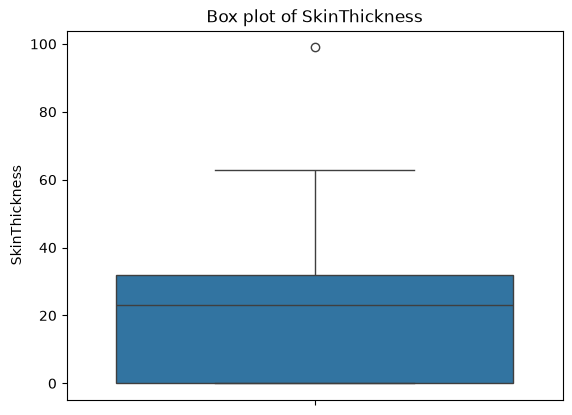

In [10]:
sns.boxplot(y=data['SkinThickness'])
ply.title('Box plot of SkinThickness')
ply.show()

In [11]:
Q1=data['Glucose'].quantile(0.25)
Q3=data['Glucose'].quantile(0.75)

IQR=Q3-Q1

lower=Q1-1.5*(IQR)
upper=Q3+1.5*(IQR)

outlier=data[
        (data['Glucose']<lower) | (data['Glucose']>upper)
]

print("Lower Boundry: " , lower)
print("Upper Boundry: " ,upper)
print("Outliers: \n",len(outlier))

outlier[['Glucose']]

Lower Boundry:  37.125
Upper Boundry:  202.125
Outliers: 
 5


,Glucose
75,0
182,0
342,0
349,0
502,0


In [12]:



print((data['Glucose']==0).sum())

5


In [13]:
outlier2=data[
        (data['BMI']<lower) | (data['BMI']>upper)
]
print(len(outlier2))

593


In [14]:
#Replace 0 with NAN in glucose , bmi , Bp bcz they contain less no of zero's
#Then delete them

data[['Glucose' , 'BMI' , 'BloodPressure']] = data[['Glucose' , 'BMI' , 'BloodPressure']].replace(0,np.nan)

data.dropna(subset=['Glucose' , 'BMI' , 'BloodPressure'] , inplace=True)

zerocount=(data==0).sum()
zeroPer=(data==0).mean()*100
zero_summary=pd.DataFrame({
    'zeros Count'  : zerocount,
    'zero Percentage': zeroPer.round(2)
})
zero_summary


,zeros Count,zero Percentage
Pregnancies,99,13.67
Glucose,0,0.00
BloodPressure,0,0.00
SkinThickness,192,26.52
Insulin,332,45.86
BMI,0,0.00
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,475,65.61


In [15]:
# Skinthickness or Insulin ky 0 ko arrange krny unki outcome ky according

data[['Insulin' , 'SkinThickness']] = data[['Insulin' , 'SkinThickness']].replace(0,np.nan)
data['Insulin'] = data['Insulin'].fillna(data.groupby('Outcome')['Insulin'].transform('median'))
data['SkinThickness'] = data['SkinThickness'].fillna(data.groupby('Outcome')['Insulin'].transform('median'))

zerocount=(data==0).sum()
zeroPer=(data==0).mean()*100
zero_summary=pd.DataFrame({
    'zeros Count'  : zerocount,
    'zero Percentage': zeroPer.round(2)
})
zero_summary

,zeros Count,zero Percentage
Pregnancies,99,13.67
Glucose,0,0.00
BloodPressure,0,0.00
SkinThickness,0,0.00
Insulin,0,0.00
BMI,0,0.00
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,475,65.61


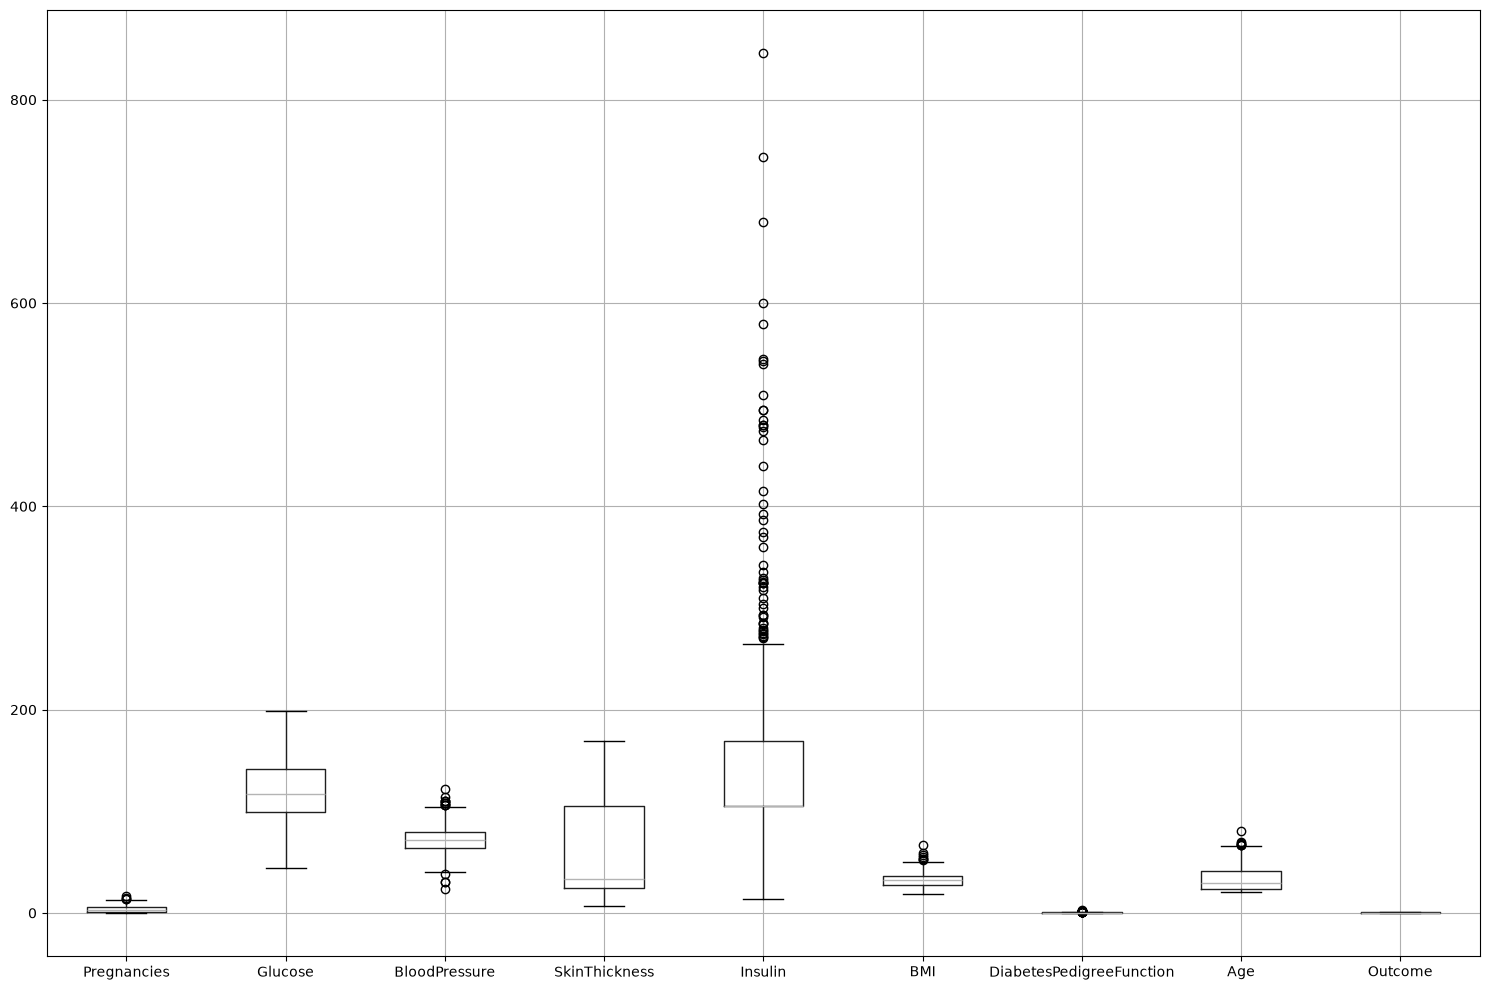

In [16]:
ply.figure(figsize=(15, 10))
data.boxplot()
ply.tight_layout()
ply.show()

In [17]:
Q1=data['Insulin'].quantile(0.25)
Q3=data['Insulin'].quantile(0.75)

IQR=Q3-Q1

lower=Q1-1.5*(IQR)
upper=Q3+1.5*(IQR)

outlierr=data[
        (data['Insulin']<lower) | (data['Insulin']>upper)
]

print("Lower Boundry: " , lower)
print("Upper Boundry: " ,upper)
print("Outliers: \n",len(outlier))

outlierr[['Insulin']]

Lower Boundry:  8.25
Upper Boundry:  266.25
Outliers: 
 5


,Insulin
8,543.0
13,846.0
53,300.0
54,342.0
56,304.0
73,270.0
111,495.0
139,325.0
144,284.0
153,485.0


In [22]:
# 1. Data ko Train aur Test mein baantne ke liye
from sklearn.model_selection import train_test_split

# 2. Random Forest Model ko use karne ke liye
from sklearn.ensemble import RandomForestClassifier

# 3. Model ka result aur accuracy check karne ke liye
from sklearn.metrics import accuracy_score, classification_report
X = data.drop(columns=['Outcome']) 
y=data['Outcome']

X_train,X_test,y_train,y_test= train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Model Accuracy: 0.8827586206896552

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.91      0.91        95
           1       0.82      0.84      0.83        50

    accuracy                           0.88       145
   macro avg       0.87      0.87      0.87       145
weighted avg       0.88      0.88      0.88       145



In [21]:
# Step 1: Naye mareez ka data aik dictionary mein likhein
# (Yaad rahe columns ka naam aur tarteeb bilkul original X jaisi honi chahiye)
new_patient = {
    'Pregnancies':[2],
    'Glucose':[120],
    'BloodPressure':[85],
    'SkinThickness':[45],
    'Insulin':[111],
    'BMI': [33.6],
    'DiabetesPedigreeFunction': [0.627],
    'Age': [45]
}



# Step 2: Is data ko DataFrame mein badlein
new_data = pd.DataFrame(new_patient)

# Step 3: Model se kahein ke Prediction kare (0 ya 1)
prediction = model.predict(new_data)

# Step 4: Model se Diabetes hone ki Probability (Percentage) bhi poochlein
probability = model.predict_proba(new_data)

# Step 5: Result ko asan alfaz mein print karein
print("--- 🩺 Prediction Result ---")
if prediction[0] == 1:
    print("Result: Positive (Diabetes has Risk..!)")
    print(f"Risk Percentage: {probability[0][1] * 100:.2f}%")
else:
    print("Result: Negative (Patient Is Healthy..!)")
    print(f"Healthy Percentage: {probability[0][0] * 100:.2f}%")

--- 🩺 Prediction Result ---
Result: Negative (Patient Is Healthy..!)
Healthy Percentage: 61.00%
